In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('bmh')

In [3]:
estado = np.array([0.10, 0.0])
x = estado[0]
v = estado[1]
m , k , g = 1.0 , 4.0 , 9.81
Cambio_de_estado = np.array([v,-k/m*x-g])


In [4]:
print(Cambio_de_estado)

[  0.   -10.21]


In [5]:
dt = 0.1
estado_siguiente = estado + dt * Cambio_de_estado
print(estado_siguiente)

[ 0.1   -1.021]


In [6]:
tiempos = [0.0]
posiciones = [estado[0]]
velocidades = [estado[1]]
tiempos.append(0.1)


In [7]:
print(tiempos)

[0.0, 0.1]


In [8]:
posiciones.append(estado_siguiente[0])
print(posiciones)

[np.float64(0.1), np.float64(0.1)]


In [9]:
velocidades.append(estado_siguiente[1])
print(velocidades)

[np.float64(0.0), np.float64(-1.0210000000000001)]


In [10]:
trayectoria = np.zeros((4, 2))
print(trayectoria)

[[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]


In [11]:
trayectoria[0,0]=0.10
print (trayectoria)

[[0.1 0. ]
 [0.  0. ]
 [0.  0. ]
 [0.  0. ]]


In [12]:
trayectoria[0,1]=0
trayectoria[1,0]= estado_siguiente[0]
trayectoria[1,1]= estado_siguiente[1]
print(trayectoria)

[[ 0.1    0.   ]
 [ 0.1   -1.021]
 [ 0.     0.   ]
 [ 0.     0.   ]]


In [13]:

trayectoria[2] = trayectoria[1]+dt*(np.array([trayectoria[1,1],-k/m*trayectoria[1,0]-g]))
print(trayectoria)

[[ 0.1     0.    ]
 [ 0.1    -1.021 ]
 [-0.0021 -2.042 ]
 [ 0.      0.    ]]


In [14]:
for n in range(3):
    print(n, n+1)

0 1
1 2
2 3


In [15]:
dt = 0.1
m , k , g = 1.0 , 4.0 , 9.81

trayectoria = np.zeros((4,2))
trayectoria[0] = np.array([0.1,0])
for n in range(3):
    trayectoria[n+1]=trayectoria[n] + dt*np.array([trayectoria[n,1],-k/m*trayectoria[n,0]-g])


In [16]:
print(trayectoria)

[[ 1.00000e-01  0.00000e+00]
 [ 1.00000e-01 -1.02100e+00]
 [-2.10000e-03 -2.04200e+00]
 [-2.06300e-01 -3.02216e+00]]


0.1


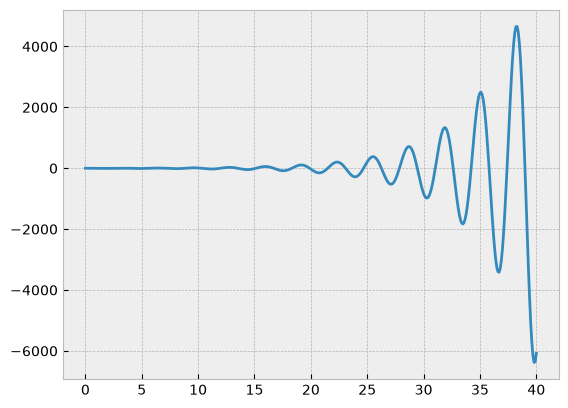

In [17]:

Npuntos = 400
t_i = 0.0
t_f = 40.0

tiempos = np.linspace(t_i, t_f, Npuntos)
dt = tiempos[1] - tiempos[0]

trayectoria = np.zeros((Npuntos, 2))

trayectoria[0] = np.array([0.1,0])

for n in range(Npuntos-1):
    trayectoria[n+1]=trayectoria[n] + dt*np.array([trayectoria[n,1],-k/m*trayectoria[n,0]-g])

datos_y = trayectoria[:,0]

plt.plot(tiempos,datos_y)
print(trayectoria[1,0])

0.10000000000000009
0.1


(-10.0, 10.0)

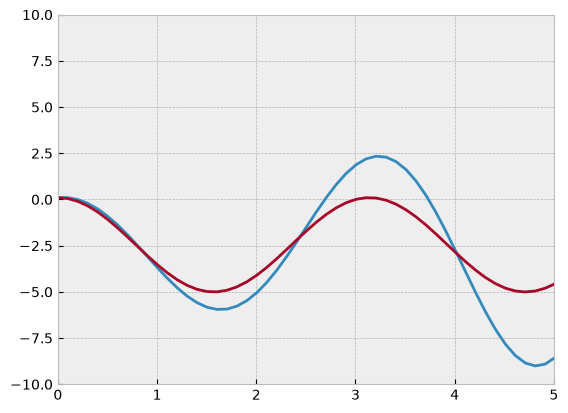

In [18]:
omega = np.sqrt(k/m)
y0 = trayectoria[0, 0]

y_analitica = (y0+g/omega**2)*np.cos(omega*tiempos)-g/omega**2

plt.plot(tiempos,datos_y)
plt.plot(tiempos,y_analitica)
print(y_analitica[0])
print(trayectoria[0, 0])
plt.xlim(0,5)
plt.ylim(-10,10)


In [19]:
Energia_euler = np.zeros(Npuntos)
for n in range(Npuntos):
    Energia_euler[n] = 1/2*m*trayectoria[n,1]**2+1/2*k*trayectoria[n,0]**2+m*g*trayectoria[n,0]

In [20]:
len(Energia_euler)
print(Energia_euler[0])

1.0010000000000001


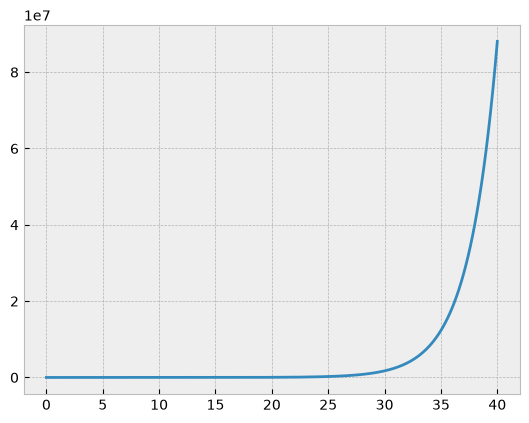

In [21]:
plt.plot(tiempos,Energia_euler)

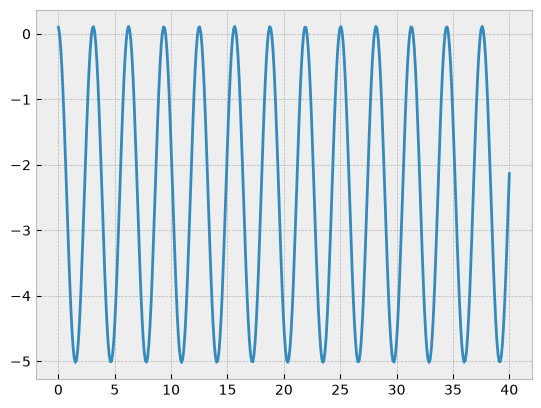

In [22]:
trayectoria_EC = np.zeros((Npuntos, 2))
trayectoria_EC[0] = np.array([0.1, 0.0])

trayectoria_EC[1,1] = trayectoria_EC[0,1]+dt*(-k/m*trayectoria_EC[0,0]-g)

trayectoria_EC[1,0] = trayectoria_EC[0,0]+dt*trayectoria_EC[1,1]

for n in range(Npuntos-1):
    trayectoria_EC[n+1,1] = trayectoria_EC[n,1]+dt*(-k/m*trayectoria_EC[n,0]-g)
    trayectoria_EC[n+1,0] = trayectoria_EC[n,0]+dt*trayectoria_EC[n+1,1]

plt.plot(tiempos,trayectoria_EC[:,0])

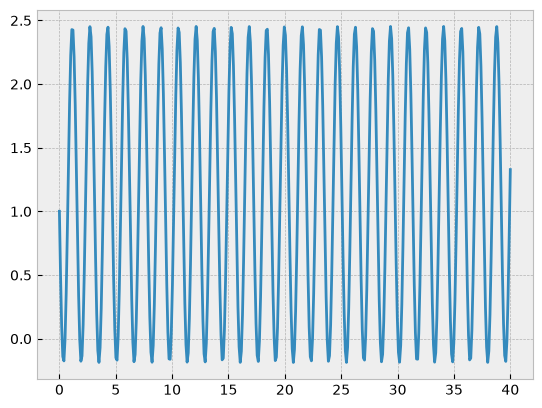

In [26]:
Energia_euler_cromer = np.zeros(Npuntos)
for n in range(Npuntos):
    Energia_euler_cromer[n] = 1/2*m*trayectoria_EC[n,1]**2+1/2*k*trayectoria_EC[n,0]**2+m*g*trayectoria_EC[n,0]
plt.plot(tiempos,Energia_euler_cromer)
#plt.plot(tiempos,Energia_euler)